# 02 — Training: SAR-only LULC semantic segmentation

Requires notebook 01 to have produced `data/metadata.csv`, `data/norm_stats.json`, `data/class_weights.json` and `data/patches/`.

**Design choices (for the report — "explain AI choices")**
- **Architecture:** U-Net with a ResNet-34 encoder. Encoder–decoder with skip connections keeps fine spatial detail (roads, field edges) that pure downsampling CNNs lose. Variant 2 is DeepLabV3+, whose atrous convolutions capture wider context — useful because single SAR pixels are noisy.
- **Transfer learning:** ImageNet-pretrained encoder (lecture 08). Low-level filters still help on SAR and training converges faster with limited data.
- **Loss:** class-weighted cross-entropy + Dice — weights counter class imbalance, Dice optimises overlap directly (closer to IoU).
- **Augmentation:** rotations/flips (SAR scenes have no canonical orientation) + small dB gain jitter (simulates calibration / incidence-angle differences).
- **Optimiser:** AdamW + cosine LR schedule, mixed precision; best checkpoint chosen by **validation mIoU** (early stopping, lecture 05).

In [1]:
%pip install -q segmentation-models-pytorch torch torchvision pandas matplotlib seaborn tqdm


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys, json, time
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt, seaborn as sns
from matplotlib.colors import ListedColormap
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

ROOT = Path.cwd().parent if (Path.cwd().parent / "s1lulc").exists() else Path.cwd()
sys.path.insert(0, str(ROOT))
from s1lulc import config as C
from s1lulc.data import S1LULCDataset, load_stats
from s1lulc.model import build_model, CEDiceLoss, confusion, metrics

DATA = ROOT / "data"; OUT = ROOT / "models"; OUT.mkdir(exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CMAP = ListedColormap(C.PALETTE)
torch.manual_seed(0); np.random.seed(0)
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

/home/jovyan/vault/DL_proj/project/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cuda NVIDIA H200 NVL


## 1. Data

In [3]:
meta = pd.read_csv(DATA / "metadata.csv"); meta = meta[meta.keep]
mean, std = load_stats(DATA / "norm_stats.json")
cw = torch.tensor(list(json.load(open(DATA / "class_weights.json")).values()), dtype=torch.float32)

ds = {s: S1LULCDataset(meta[meta.split == s], DATA / "patches", mean, std, augment=(s == "train"))
      for s in ["train", "val", "test"]}
BATCH = 32
dl = {s: DataLoader(d, batch_size=BATCH, shuffle=(s == "train"), num_workers=0, pin_memory=True, drop_last=(s == "train"))
      for s, d in ds.items()}
{s: len(d) for s, d in ds.items()}

{'train': 2160, 'val': 432, 'test': 432}

## 2. Training loop

In [4]:
@torch.no_grad()
def evaluate(model, loader, loss_fn):
    model.eval(); cm = np.zeros((C.NUM_CLASSES,) * 2, np.int64); tot = 0.0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.autocast(DEVICE, enabled=DEVICE == "cuda"):
            logits = model(x)
        tot += loss_fn(logits.float(), y).item() * len(x)
        cm += confusion(logits.argmax(1), y)
    return tot / len(loader.dataset), cm

def train(name, arch="Unet", encoder="resnet34", epochs=30, lr=3e-4, patience=8):
    model = build_model(arch, encoder).to(DEVICE)
    loss_fn = CEDiceLoss(cw.to(DEVICE))
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    scaler = torch.cuda.amp.GradScaler(enabled=DEVICE == "cuda")
    hist, best, wait = [], -1, 0
    for ep in range(1, epochs + 1):
        model.train(); t0 = time.time(); run = 0.0; cm = np.zeros((C.NUM_CLASSES,) * 2, np.int64)
        for x, y in tqdm(dl["train"], leave=False, desc=f"{name} ep{ep}"):
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            with torch.autocast(DEVICE, enabled=DEVICE == "cuda"):
                logits = model(x)
            loss = loss_fn(logits.float(), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            run += loss.item() * len(x); cm += confusion(logits.argmax(1).detach(), y)
        sched.step()
        tr = metrics(cm); vl, vcm = evaluate(model, dl["val"], loss_fn); va = metrics(vcm)
        hist.append({"epoch": ep, "train_loss": run / len(dl["train"].dataset), "val_loss": vl,
                     "train_mIoU": tr["mIoU"], "val_mIoU": va["mIoU"], "train_OA": tr["OA"], "val_OA": va["OA"]})
        print(f"ep{ep:02d} loss {hist[-1]['train_loss']:.3f}/{vl:.3f}  mIoU {tr['mIoU']:.3f}/{va['mIoU']:.3f}  "
              f"OA {tr['OA']:.3f}/{va['OA']:.3f}  {time.time()-t0:.0f}s")
        if va["mIoU"] > best:
            best, wait = va["mIoU"], 0
            torch.save({"state_dict": model.state_dict(), "arch": arch, "encoder": encoder,
                        "classes": C.CLASSES, "bands": C.S1_BANDS, "mean": mean.tolist(), "std": std.tolist()},
                       OUT / f"{name}.pt")
        else:
            wait += 1
            if wait >= patience: print("early stop"); break
    h = pd.DataFrame(hist); h.to_csv(OUT / f"{name}_history.csv", index=False)
    return h

def plot_history(h, name):
    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    for a, k in zip(ax, ["loss", "mIoU", "OA"]):
        a.plot(h.epoch, h[f"train_{k}"], label="train"); a.plot(h.epoch, h[f"val_{k}"], label="val")
        a.set_title(f"{name} — {k}"); a.set_xlabel("epoch"); a.legend(); a.grid(alpha=.3)
    plt.tight_layout(); plt.savefig(OUT / f"{name}_curves.png", dpi=150); plt.show()

## 3. Variant A — U-Net / ResNet-34 (baseline)

unet_r34 ep1:   0%|          | 0/67 [00:00<?, ?it/s]

unet_r34 ep1:   1%|▏         | 1/67 [00:02<02:53,  2.63s/it]

unet_r34 ep1:   3%|▎         | 2/67 [00:03<01:30,  1.40s/it]

unet_r34 ep1:   4%|▍         | 3/67 [00:03<00:55,  1.15it/s]

unet_r34 ep1:   6%|▌         | 4/67 [00:03<00:35,  1.76it/s]

unet_r34 ep1:   7%|▋         | 5/67 [00:03<00:24,  2.50it/s]

... (1,259 outputs left out)

unet_r34 ep19:  97%|█████████▋| 65/67 [00:25<00:00,  2.38it/s]

unet_r34 ep19:  99%|█████████▊| 66/67 [00:25<00:00,  3.01it/s]

unet_r34 ep19: 100%|██████████| 67/67 [00:26<00:00,  3.19it/s]

ep19 loss 0.689/1.014  mIoU 0.612/0.534  OA 0.783/0.747  31s
early stop


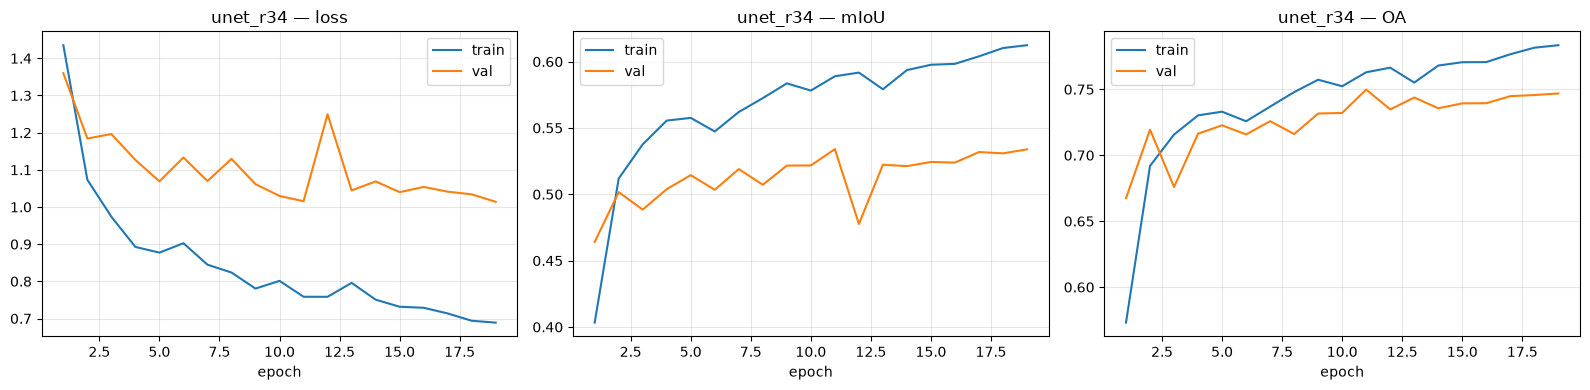

In [5]:
hA = train("unet_r34", "Unet", "resnet34")
plot_history(hA, "unet_r34")

## 4. Variant B — DeepLabV3+ / ResNet-34

deeplab_r34 ep1:   0%|          | 0/67 [00:00<?, ?it/s]

deeplab_r34 ep1:   1%|▏         | 1/67 [00:01<01:38,  1.50s/it]

deeplab_r34 ep1:   3%|▎         | 2/67 [00:01<00:56,  1.16it/s]

deeplab_r34 ep1:   4%|▍         | 3/67 [00:02<00:46,  1.39it/s]

deeplab_r34 ep1:   6%|▌         | 4/67 [00:03<00:50,  1.24it/s]

deeplab_r34 ep1:   7%|▋         | 5/67 [00:03<00:42,  1.45it/s]

... (1,496 outputs left out)

deeplab_r34 ep24:  96%|█████████▌| 64/67 [00:21<00:01,  2.40it/s]

deeplab_r34 ep24:  97%|█████████▋| 65/67 [00:22<00:00,  2.72it/s]

deeplab_r34 ep24: 100%|██████████| 67/67 [00:22<00:00,  4.21it/s]

ep24 loss 0.614/1.062  mIoU 0.631/0.527  OA 0.799/0.746  26s
early stop


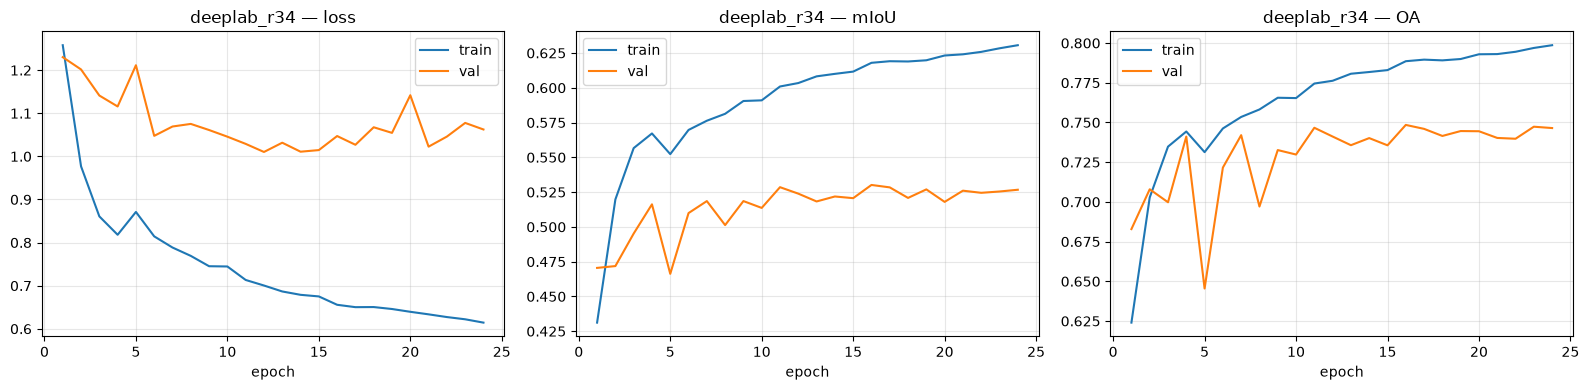

In [6]:
hB = train("deeplab_r34", "DeepLabV3Plus", "resnet34")
plot_history(hB, "deeplab_r34")

## 5. Variant C — U-Net without ImageNet pretraining (ablation: does transfer learning help?)

unet_r34_scratch ep1:   0%|          | 0/67 [00:00<?, ?it/s]

unet_r34_scratch ep1:   1%|▏         | 1/67 [00:00<00:31,  2.08it/s]

unet_r34_scratch ep1:   3%|▎         | 2/67 [00:00<00:26,  2.48it/s]

unet_r34_scratch ep1:   6%|▌         | 4/67 [00:01<00:18,  3.46it/s]

unet_r34_scratch ep1:   7%|▋         | 5/67 [00:01<00:21,  2.91it/s]

unet_r34_scratch ep1:   9%|▉         | 6/67 [00:02<00:23,  2.64it/s]

... (1,867 outputs left out)

unet_r34_scratch ep30:  97%|█████████▋| 65/67 [00:22<00:00,  2.33it/s]

unet_r34_scratch ep30:  99%|█████████▊| 66/67 [00:23<00:00,  2.25it/s]

unet_r34_scratch ep30: 100%|██████████| 67/67 [00:23<00:00,  2.82it/s]

ep30 loss 0.792/1.076  mIoU 0.578/0.511  OA 0.754/0.735  27s


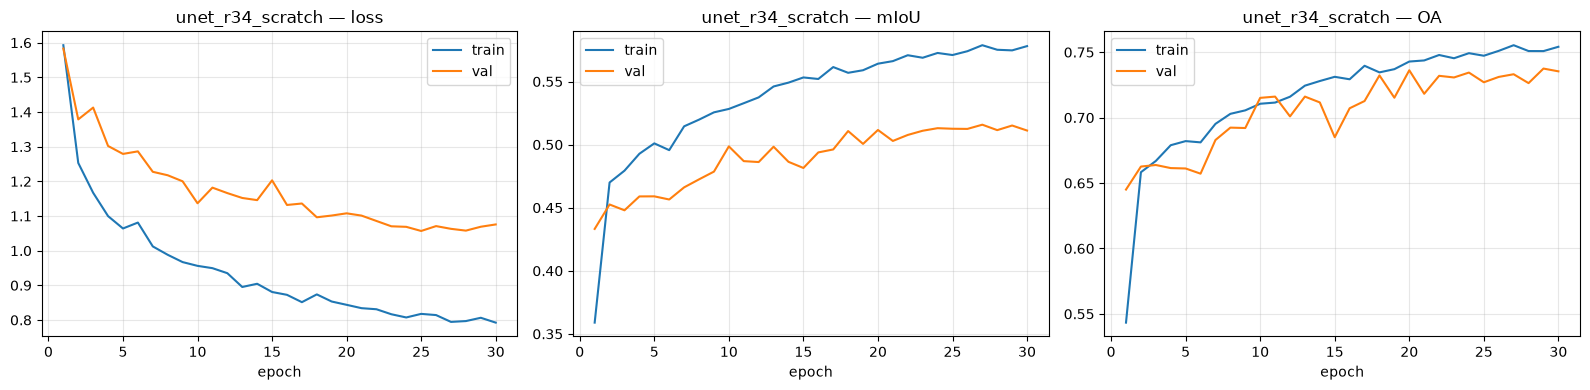

In [7]:
def train_scratch():
    global build_model
    _orig = build_model
    build_model = lambda a, e: _orig(a, e, pretrained=False)
    try:
        return train("unet_r34_scratch", "Unet", "resnet34")
    finally:
        build_model = _orig
hC = train_scratch()
plot_history(hC, "unet_r34_scratch")

## 6. Test-set evaluation and comparison

In [8]:
def load(name):
    ck = torch.load(OUT / f"{name}.pt", map_location=DEVICE)
    m = build_model(ck["arch"], ck["encoder"], pretrained=False).to(DEVICE); m.load_state_dict(ck["state_dict"]); return m

loss_fn = CEDiceLoss(cw.to(DEVICE)); results, cms = [], {}
for name in ["unet_r34", "deeplab_r34", "unet_r34_scratch"]:
    if not (OUT / f"{name}.pt").exists(): continue
    _, cm = evaluate(load(name), dl["test"], loss_fn); m = metrics(cm); cms[name] = cm
    results.append({"model": name, "OA": m["OA"], "mIoU": m["mIoU"], "mF1": m["mF1"],
                    **{f"IoU {c}": v for c, v in zip(C.CLASSES, m["IoU"])},
                    **{f"F1 {c}": v for c, v in zip(C.CLASSES, m["F1"])}})
res = pd.DataFrame(results).set_index("model"); res.to_csv(OUT / "test_results.csv")
res.T.round(3)

model,unet_r34,deeplab_r34,unet_r34_scratch
OA,0.721,0.715,0.682
mIoU,0.509,0.499,0.480
mF1,0.625,0.613,0.600
IoU Water,0.908,0.900,0.899
IoU Built-up,0.641,0.633,0.626
IoU Tree cover,0.522,0.536,0.520
IoU Cropland,0.651,0.635,0.529
IoU Grass/Shrub/Wetland,0.265,0.243,0.245
IoU Bare/Sparse,0.066,0.048,0.059
F1 Water,0.952,0.947,0.947


best model: unet_r34


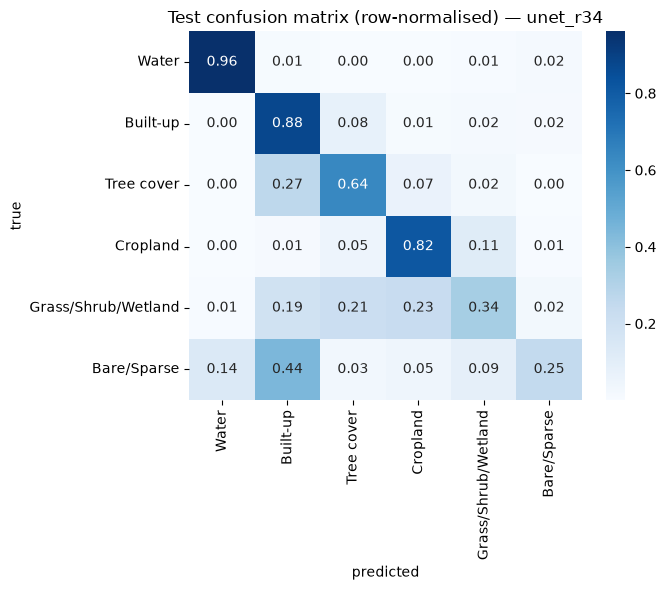

In [9]:
best = res.mIoU.idxmax(); print("best model:", best)
cm = cms[best]; cmn = cm / cm.sum(1, keepdims=True)
plt.figure(figsize=(7, 6))
sns.heatmap(cmn, annot=True, fmt=".2f", xticklabels=C.CLASSES, yticklabels=C.CLASSES, cmap="Blues")
plt.xlabel("predicted"); plt.ylabel("true"); plt.title(f"Test confusion matrix (row-normalised) — {best}")
plt.tight_layout(); plt.savefig(OUT / "confusion_matrix.png", dpi=150); plt.show()

## 7. Qualitative examples (test set)

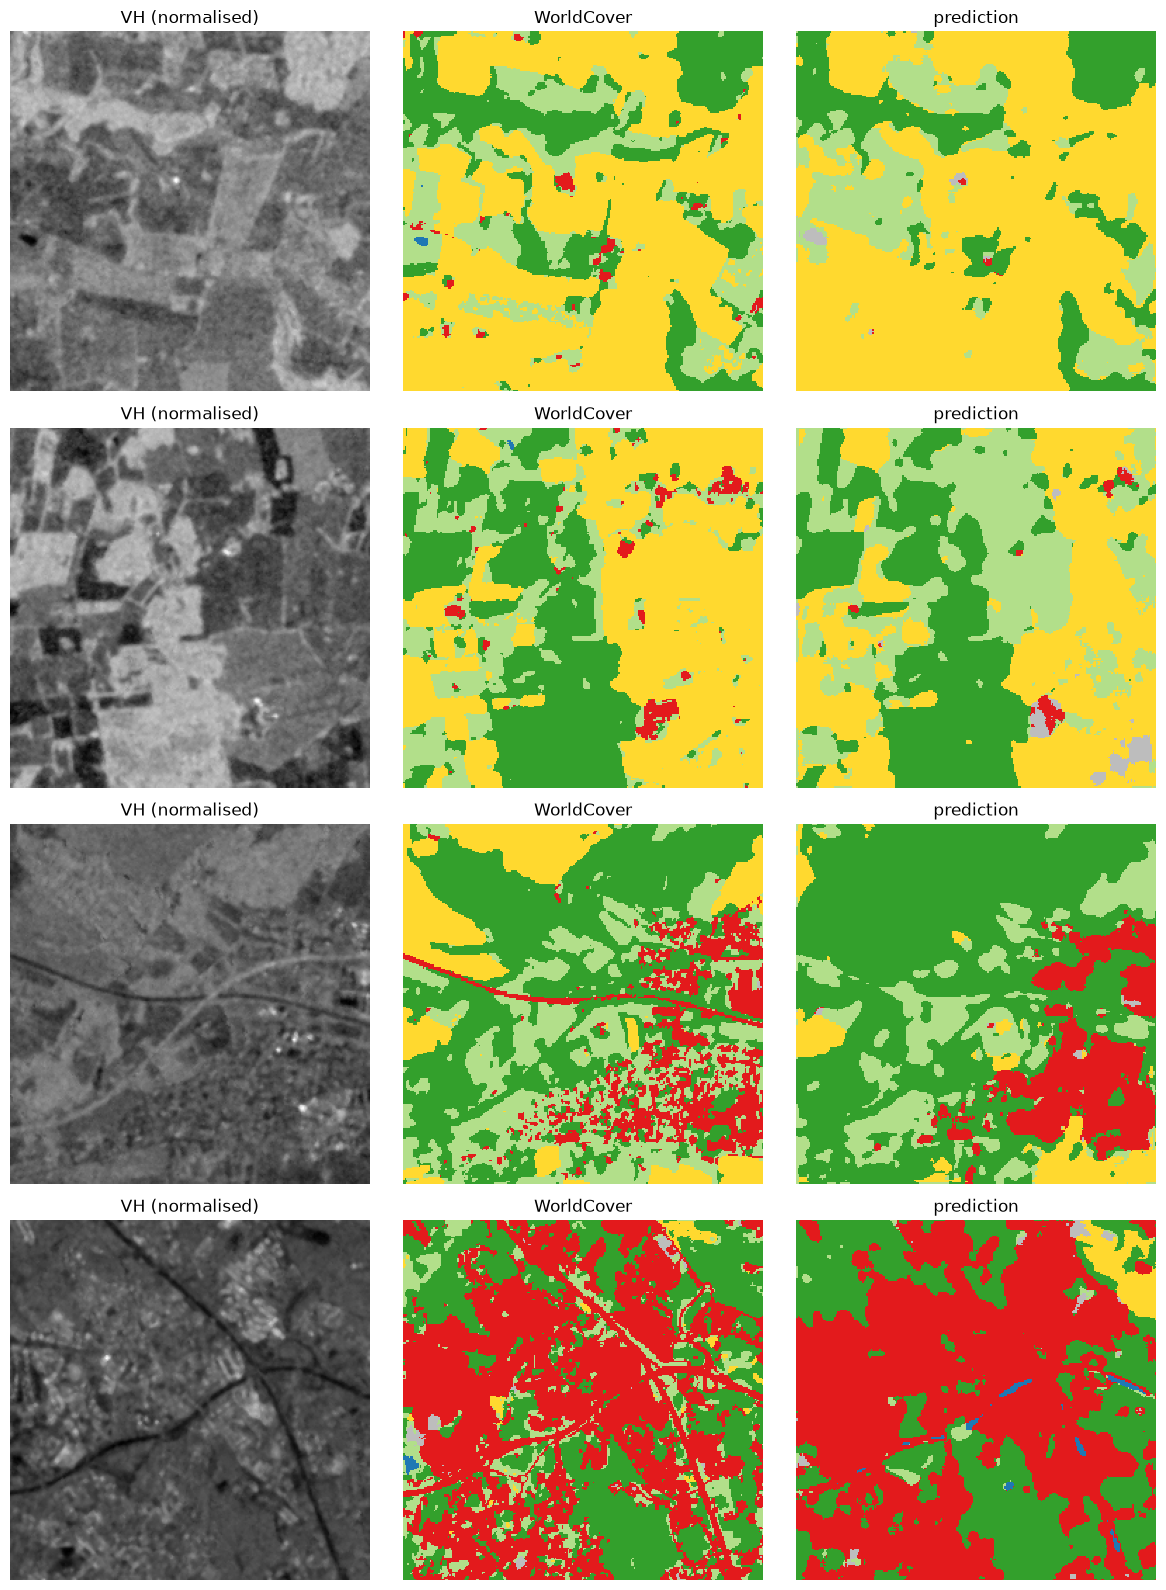

In [10]:
model = load(best); model.eval()
idx = np.random.RandomState(3).choice(len(ds["test"]), 4, replace=False)
fig, ax = plt.subplots(4, 3, figsize=(12, 16))
for r, i in enumerate(idx):
    x, y = ds["test"][i]
    with torch.no_grad(): p = model(x[None].to(DEVICE)).argmax(1)[0].cpu()
    ax[r, 0].imshow(x[1], cmap="gray"); ax[r, 0].set_title("VH (normalised)")
    yy = y.numpy().astype(float); yy[yy == C.IGNORE_INDEX] = np.nan
    ax[r, 1].imshow(yy, cmap=CMAP, vmin=0, vmax=C.NUM_CLASSES - 1, interpolation="nearest"); ax[r, 1].set_title("WorldCover")
    ax[r, 2].imshow(p, cmap=CMAP, vmin=0, vmax=C.NUM_CLASSES - 1, interpolation="nearest"); ax[r, 2].set_title("prediction")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(OUT / "test_examples.png", dpi=120); plt.show()

In [11]:
import shutil
shutil.copy(OUT / f"{best}.pt", OUT / "best_model.pt")
print("saved", OUT / "best_model.pt")

saved /home/jovyan/vault/DL_proj/project/models/best_model.pt
